# DistilBERT Model

Purpose of this notebook: Fine-tune one pretrained DistilBERT encoder with a three-class classification head, evaluate it on the validation split, and save predictions and mistakes for our  error inspection.
- Training: 2,947 sentences from the Financial PhraseBank 66% agreement subset
- Validation: 632 sentences
- Label mapping: 0 = negative, 1 = neutral, 2 = positive
- Main metric: macro-F1, because class frequencies are imbalanced
- Starting checkpoint: distilbert-base-uncased — generic pretrained encoder, not a financial-sentiment checkpoint trained on the full PhraseBank
Our earlier 03_baseline_model.ipynb (TF-IDF + Logistic Regression) remains a separate classical reference. The goal here is to establish the neural model that can later be retrained from the same original pretrained checkpoint under baseline, random-data and targeted-data conditions.


In [1]:
import sys

print(sys.executable)
from pathlib import Path
import gc
import json
import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix




/Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/.venv-bert/bin/python


/Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/.venv-bert/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Interpreter:", sys.executable)
print("PyTorch:", torch.__version__)
print("Device:", device)

Interpreter: /Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/.venv-bert/bin/python
PyTorch: 2.2.2
Device: cpu


## Data load


In [3]:

path = Path("Financial Phrasebank Project/data/splits")
train_df= pd.read_csv(path/"train.csv")
validation_df= pd.read_csv(path/"validation.csv")
print("Training samples: ", len(train_df))
print("Validation samples: ", len(validation_df))

Training samples:  2947
Validation samples:  632


In [4]:
RANDOM_STATE= 42
LABELS= {0: "negative", 1: "neutral", 2: "positive"}
CLASS_ORDER= [0,1,2]
expected_col= {"sentence", "sentence_clean", "label"}
LABEL2ID = {name: i for i, name in LABELS.items()}
for split_name, frame in [("train", train_df), ("validation", validation_df)]:
    assert expected_col.issubset(frame.columns), f"Missing columns in {split_name}"
    assert frame[list(expected_col)].notna().all().all(), f"Missing values in {split_name}"
    assert set(frame["label"].unique()) == set(CLASS_ORDER), f"Unexpected labels in {split_name}"
    assert not frame["sentence_clean"].duplicated().any(), f"Duplicates in {split_name}"
    
    assert len(train_df) == 2947 and len(validation_df) == 632, "Unexpected split size — verify repository branch"
    summary = pd.DataFrame({
    "train_count": train_df["label"].value_counts().reindex(CLASS_ORDER),
    "validation_count": validation_df["label"].value_counts().reindex(CLASS_ORDER).reindex(CLASS_ORDER),
})
summary.index = [LABELS[i] for i in CLASS_ORDER]
summary

,train_count,validation_count
negative,360,77
neutral,1770,379
positive,817,176


## 4. DistilBERT tokenization
DistilBERT breaks the text into subword tokens and generates input_ids plus an attention_mask. A fixed maximum length lets us batch sentences efficiently.

Important: from_pretrained loads the tokenizer's existing vocabulary; it does not learn a new vocabulary from our validation set

In [5]:
X_train = train_df["sentence"].astype(str).tolist()
X_validation = validation_df["sentence"].astype(str).tolist()
y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = validation_df["label"].to_numpy(dtype=np.int64)

In [6]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(X_train, truncation=True, padding="max_length",max_length=MAX_LENGTH, return_tensors="pt")
val_encodings = tokenizer( X_validation, truncation=True, padding="max_length",max_length=MAX_LENGTH, return_tensors="pt")

train_lengths = [len(ids) for ids in tokenizer(X_train, truncation=False)["input_ids"]]
truncated = sum(length > MAX_LENGTH for length in train_lengths)
print("Training sequences above MAX_LENGTH:", truncated, "of", len(train_lengths))
print("Training input IDs:", tuple(train_encodings["input_ids"].shape))
print("Validation input IDs:", tuple(val_encodings["input_ids"].shape))
print("Example tokens:", tokenizer.tokenize(X_train[0])[:35])

Training sequences above MAX_LENGTH: 1 of 2947
Training input IDs: (2947, 128)
Validation input IDs: (632, 128)
Example tokens: ['the', 'biggest', 'sellers', 'in', 'the', 'chain', "'", 's', 'supermarkets', 'in', 'finland', 'are', 'organic', 'pi', '##rk', '##ka', 'tomatoes', ',', 'carrot', '##s', ',', 'eggs', ',', 'and', 'meat', 'products', '.']


### Model



In [7]:

train_dataset = [
    {"input_ids": train_encodings["input_ids"][i],"attention_mask": train_encodings["attention_mask"][i], "labels": torch.tensor(y_train[i], dtype=torch.long)}
    for i in range(len(y_train))]


val_dataset = [
    {"input_ids": val_encodings["input_ids"][i],"attention_mask": val_encodings["attention_mask"][i], "labels": torch.tensor(y_val[i], dtype=torch.long)} for i in range(len(y_val))]

train_loader = DataLoader(train_dataset,batch_size=16,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=16,shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 185
Validation batches: 40


In [8]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=LABELS,
    label2id=LABEL2ID,
)
model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print("Trainable model parameters:", f"{n_params:,}")
print("Labels:", model.config.id2label)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable model parameters: 66,955,779
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


In [9]:
lr = 2e-5
weight_decay = 0.01
EPOCHS = 3
PATIENCE = 2

output_dir = Path("results/distilbert_baseline")
model_dir = output_dir / "best_model"
output_dir.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=lr, weight_decay=weight_decay
)

@torch.no_grad()
def evaluate_model(current_model, loader):
    current_model.eval()
    all_true= []
    all_pred= []
    all_probs=[]
    total_loss = 0.0
    total_n = 0

    for batch in loader:
        batch = {name: tensor.to(device) for name, tensor in batch.items()}
        outputs = current_model(**batch)
        probabilities = torch.softmax(outputs.logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        batch_n = batch["labels"].size(0)
        total_loss += outputs.loss.item() * batch_n
        total_n += batch_n
        all_true.extend(batch["labels"].cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())
        all_probs.append(probabilities.cpu().numpy())

    return {
        "loss": total_loss / total_n,
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(all_true, all_pred, average="macro", labels=CLASS_ORDER, zero_division=0),
        "true": np.asarray(all_true),
        "pred": np.asarray(all_pred),
        "probabilities": np.vstack(all_probs),
    }


## Optimization of epochs and batches

In [12]:
history= []
best_f1= -1.0
best_epoch= None
no_improvement= 0

for epoch in range(1, EPOCHS + 1):
    start= time.perf_counter()
    model.train()
    total_train_loss = 0.0
    total_train_examples = 0

    for step, batch in enumerate(train_loader, start=1):
        batch= {name: tensor.to(device) for name, tensor in batch.items()}
        optimizer.zero_grad()

        outputs= model(**batch)
        loss= outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        batch_n= batch["labels"].size(0)
        total_train_loss+= loss.item() * batch_n
        total_train_examples+= batch_n

        if step % 50== 0 or step== len(train_loader):
            print(f"Epoch {epoch}/{EPOCHS} - batch {step}/{len(train_loader)}")

    train_loss= total_train_loss / total_train_examples
    val_metrics= evaluate_model(model, val_loader)
    epoch_seconds= time.perf_counter() - start

    history.append({"epoch": epoch,"train_loss": train_loss, "val_loss": val_metrics["loss"],"val_accuracy": val_metrics["accuracy"],"val_macro_f1": val_metrics["macro_f1"],"seconds": epoch_seconds, })

    print(
        f"Epoch {epoch}: train loss={train_loss:.4f}, " f"val loss={val_metrics['loss']:.4f}, "f"val accuracy={val_metrics['accuracy']:.4f}, " f"va macro-F1={val_metrics['macro_f1']:.4f}, " f"time={epoch_seconds:.1f}s")

    if val_metrics["macro_f1"] > best_f1 + 1e-4:
        best_f1= val_metrics["macro_f1"]
        best_epoch= epoch
        no_improvement= 0
        model.save_pretrained(model_dir)
        tokenizer.save_pretrained(model_dir)
        print("  Saved improved checkpoint.")
    else:
        no_improvement+= 1
        if no_improvement>= PATIENCE:
            print("Stopping early: validation macro-F1 did not improve.")
            break

history_df = pd.DataFrame(history)
#display(history_df)
print(f"Best epoch: {best_epoch} | best validation macro-F1: {best_f1:.4f}")

Epoch 1/3 - batch 50/185
Epoch 1/3 - batch 100/185
Epoch 1/3 - batch 150/185
Epoch 1/3 - batch 185/185
Epoch 1: train loss=0.5955, val loss=0.3551, val accuracy=0.8576, val macro-F1=0.8248, time=654.1s
  Saved improved checkpoint.
Epoch 2/3 - batch 50/185
Epoch 2/3 - batch 100/185
Epoch 2/3 - batch 150/185
Epoch 2/3 - batch 185/185
Epoch 2: train loss=0.2627, val loss=0.3616, val accuracy=0.8703, val macro-F1=0.8552, time=597.0s
  Saved improved checkpoint.
Epoch 3/3 - batch 50/185
Epoch 3/3 - batch 100/185
Epoch 3/3 - batch 150/185
Epoch 3/3 - batch 185/185
Epoch 3: train loss=0.1335, val loss=0.5037, val accuracy=0.8750, val macro-F1=0.8489, time=610.6s
Best epoch: 2 | best validation macro-F1: 0.8552


## Validation and test 


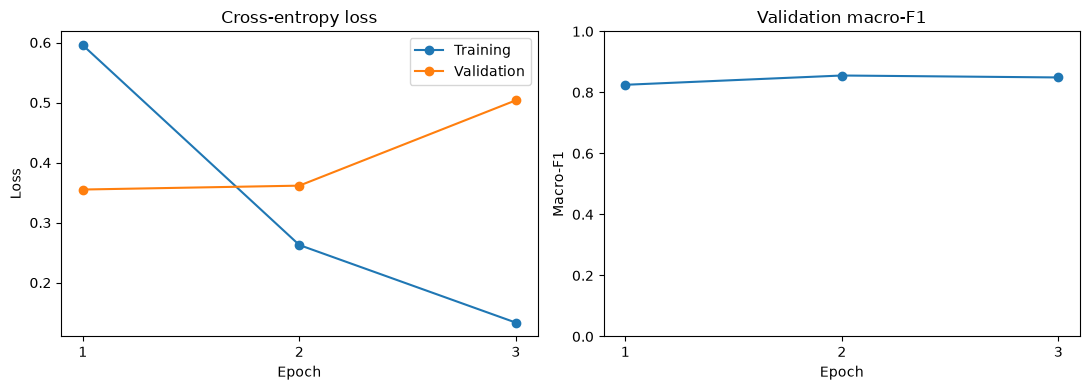

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], marker="o")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1))
for ax in axes:
    ax.set_xticks(history_df["epoch"])
plt.tight_layout()
plt.show()

Validation accuracy: 0.8703
Validation macro-F1: 0.8552

Classification report:
              precision    recall  f1-score   support

    negative      0.863     0.818     0.840        77
     neutral      0.956     0.855     0.903       379
    positive      0.741     0.926     0.823       176

    accuracy                          0.870       632
   macro avg      0.853     0.866     0.855       632
weighted avg      0.885     0.870     0.873       632



,Predicted negative,Predicted neutral,Predicted positive
Actual negative,63,3,11
Actual neutral,9,324,46
Actual positive,1,12,163


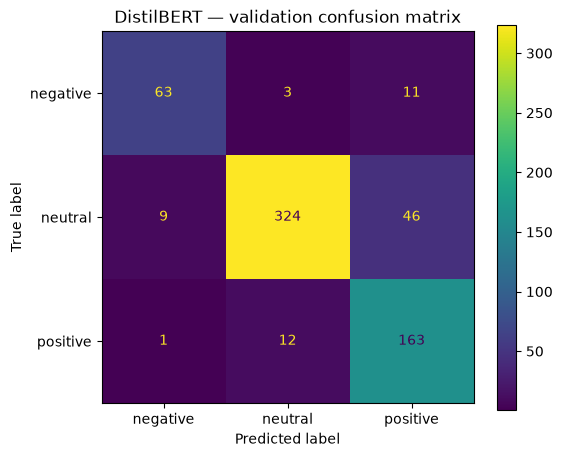

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = AutoModelForSequenceClassification.from_pretrained(model_dir)
best_model.to(device)

val_results = evaluate_model(best_model, val_loader)
y_pred = val_results["pred"]

print(f"Validation accuracy: {val_results['accuracy']:.4f}")
print(f"Validation macro-F1: {val_results['macro_f1']:.4f}")
print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred,
    labels=CLASS_ORDER,
    target_names=[LABELS[i] for i in CLASS_ORDER],
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(y_val, y_pred, labels=CLASS_ORDER)
display(pd.DataFrame(
    cm,
    index=["Actual " + LABELS[i] for i in CLASS_ORDER],
    columns=["Predicted " + LABELS[i] for i in CLASS_ORDER],
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=[LABELS[i] for i in CLASS_ORDER]).plot(ax=ax)
ax.set_title("DistilBERT — validation confusion matrix")
plt.show()

In [16]:
predictions_df = validation_df[["sentence", "label"]].copy().reset_index(drop=True)
predictions_df["true_sentiment"] = predictions_df["label"].map(LABELS)
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_sentiment"] = predictions_df["predicted_label"].map(LABELS)
predictions_df["correct"] = predictions_df["label"] == predictions_df["predicted_label"]

for i, name in LABELS.items():
    predictions_df[f"prob_{name}"] = val_results["probabilities"][:, i]
predictions_df["confidence"] = val_results["probabilities"].max(axis=1)

errors_df = predictions_df.loc[~predictions_df["correct"]].copy()

print("Misclassified validation sentences:", len(errors_df))
display(errors_df[["sentence", "true_sentiment", "predicted_sentiment", "confidence"]].head(20))

Misclassified validation sentences: 82


,sentence,true_sentiment,predicted_sentiment,confidence
7,The company plans to increase the unit 's spec...,neutral,positive,0.970655
8,"AGJ recorded EUR 43 mln sales in 2006 , most o...",neutral,positive,0.673276
14,The prosecutor is also demanding Outokumpu pay...,negative,neutral,0.688000
17,The difference can be explained by the fact th...,neutral,negative,0.645818
22,HELSINKI ( AFX ) - Outokumpu said it has agree...,neutral,positive,0.797247
46,Outotec is currently delivering a new oil shal...,neutral,positive,0.586563
51,It expects revenue between $ 8.4 billion and $...,neutral,positive,0.731852
65,"Beef imports fell slightly from 2006 , to 14mn...",neutral,negative,0.927442
69,The sale of the Healthcare Trade business supp...,positive,neutral,0.636587
95,The offer represents a premium of 24 % over th...,positive,neutral,0.916361
